Superstore Sales : Data anylisis and visualization

In [1]:

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder   # added LabelEncoder (needed for encoding later)
from pathlib import Path

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

# Folders for saved files (created if they don't exist)
PROCESSED_DIR = Path("data/processed")
FIG_DIR = Path("reports/figures")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Function to save a chart as a picture
def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

<!-- 1. Data collection and Exploration -->

In [9]:
# 1.1 Load the dataset with pandas

df = pd.read_csv('superstore_raw.csv', encoding='latin-1') # latin-1 encoding handles special characters in this file
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [13]:
# 1.2 Structure: rows, columns,  datatypes

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.info()

Rows: 9994
Columns: 21
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 

In [ ]:
# 1.3  Summary statistics for numeric and text columns

display(df.describe().round(2))
display(df.describe(include='object'))

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00,9994.00,9994.00
mean,4997.50,55190.38,229.86,3.79,0.16,28.66
std,2885.16,32063.69,623.25,2.23,0.21,234.26
min,1.00,1040.00,0.44,1.00,0.00,-6599.98
25%,2499.25,23223.00,17.28,2.00,0.00,1.73
50%,4997.50,56430.50,54.49,3.00,0.20,8.67
75%,7495.75,90008.00,209.94,5.00,0.20,29.36
max,9994.00,99301.00,22638.48,14.00,0.80,8399.98


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994
unique,5009,1237,1334,4,793,793,3,1,531,49,4,1862,3,17,1850
top,CA-2017-100111,9/5/2016,12/16/2015,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope
freq,14,38,35,5968,37,37,5191,9994,915,2001,3203,19,6026,1523,48


In [ ]:
# 1.4 Spot potential problems
# checks: missing values, duplicates,impossible value.
# Check 1:
print("Missing values in each column:")
print(df.isnull().sum()) # checks missing values

# Check 2:
print("\nDuplicate rows:", df.duplicated().sum()) # Checks duplicate rows

# Check 3: checks impossible values
print("\nNegative sales:", (df["Sales"] < 0).sum()) 
print("Quantity of zero or less:", (df["Quantity"] <= 0).sum())
print("Discount outside 0 to 1:", ((df["Discount"] < 0) | (df["Discount"] > 1)).sum())

# Check 4: checks how many orders lost money
print("\nOrders with negative profit:", (df["Profit"] < 0).sum())


Missing values in each column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate rows: <bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
9989    False
9990    False
9991    False
9992    False
9993    False
Length: 9994, dtype: bool>

Negative sales: 0
Quantity of zero or less: 0
Discount outside 0 to 1: 0

Orders with negative profit: 1871


In [19]:
print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "None")
print("\nUnique values per column:")
print(df.nunique())
print("\nSkewness of numeric columns (|skew| > 1 means heavily skewed):")
print(df[["Sales", "Quantity", "Discount", "Profit"]].skew().round(2))

Missing values per column:
 None

Unique values per column:
Row ID           9994
Order ID         5009
Order Date       1237
Ship Date        1334
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              531
State              49
Postal Code       631
Region              4
Product ID       1862
Category            3
Sub-Category       17
Product Name     1850
Sales            5825
Quantity           14
Discount           12
Profit           7287
dtype: int64

Skewness of numeric columns (|skew| > 1 means heavily skewed):
Sales       12.97
Quantity     1.28
Discount     1.68
Profit       7.56
dtype: float64


2. Data Cleaning and Transformation

2.1 Fix data types and inconsistent text

In [ ]:
# Strip whitespace from all text columns

# 2.1 Fix data types and inconsistent text

# Step 1: Remove extra spaces from all text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    df[c] = df[c].str.strip()

# Step 2: Convert dates from text to real dates (month/day/year)
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y"
)
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], 
    format="%m/%d/%Y"
)

# Step 3: Fix postal codes
df["Postal Code"] = df["Postal Code"].astype(str).str.zfill(5) # makes every postal code 5 char long by adding zero to the left.

# Step 4: Remove duplicate rows 
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", before - len(df))

# Step 5: Check that the changes worked
print(df.dtypes)

Duplicates removed: 0
Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


2.2 Handling missing values

In [23]:
key_cols = ["Order ID", "Order Date", "Customer ID", "Product ID"]
n_before = len(df)
df = df.dropna(subset=key_cols)

num_cols_all = df.select_dtypes(include="number").columns.drop("Row ID") # finds numerical columns
cat_cols_all = df.select_dtypes(include=["object", "string"]).columns # finds categorical data/text
n_imputed = int(
    df[num_cols_all].isna().sum().sum() # cunts missing values in numerical and text columns
    + df[cat_cols_all].isna().sum().sum()
)
df[num_cols_all] = df[num_cols_all].fillna( # fill missing values with the median
    df[num_cols_all].median()
)
for c in cat_cols_all: #for missing categorical values 
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mode()[0])   

print(
    f"Rows dropped for missing keys: {n_before - len(df)} | "
    f"cells imputed: {n_imputed}"
)

print(
    "Remaining missing values:",
    int(df.isna().sum().sum())
)


Rows dropped for missing keys: 0 | cells imputed: 0
Remaining missing values: 0


2.3 Outlier detection: box plots + IQR rule

In [24]:
outlier_cols = ["Sales", "Quantity", "Discount", "Profit"]

def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for c in outlier_cols:
    lo, hi = iqr_bounds(df[c])
    z = (df[c] - df[c].mean()) / df[c].std()
    rows.append({
        "column": c, "lower_bound": round(lo, 2), "upper_bound": round(hi, 2),
        "IQR outliers": int(((df[c] < lo) | (df[c] > hi)).sum()),
        "% of rows": round(((df[c] < lo) | (df[c] > hi)).mean() * 100, 1),
        "|z|>3 outliers": int((z.abs() > 3).sum()),
    })
outlier_summary = pd.DataFrame(rows).set_index("column")
outlier_summary

,lower_bound,upper_bound,IQR outliers,% of rows,|z|>3 outliers
column,,,,,
Sales,-271.71,498.93,1167,11.7,127
Quantity,-2.50,9.50,170,1.7,113
Discount,-0.30,0.50,856,8.6,300
Profit,-39.72,70.82,1881,18.8,107


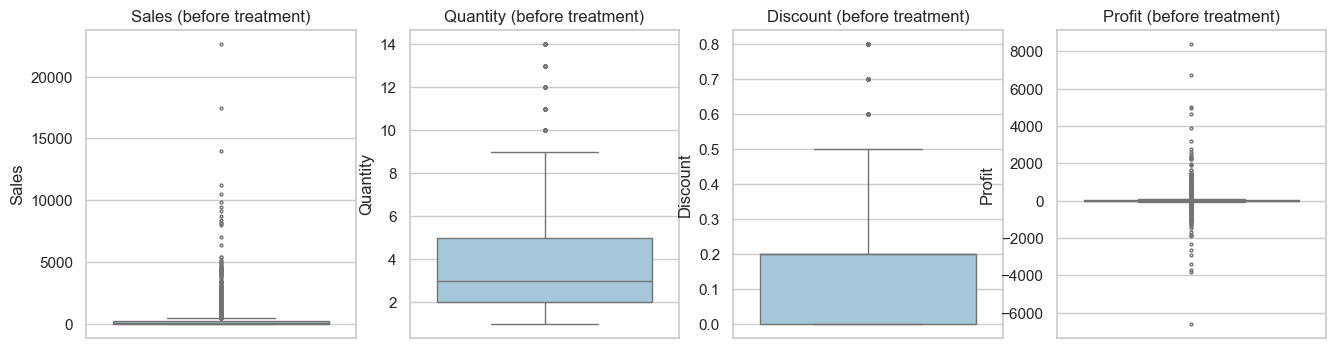

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, outlier_cols):
    sns.boxplot(y=df[c], ax=ax, color="#9ecae1", fliersize=2)
    ax.set_title(f"{c} (before treatment)")

plt.show()
   

2.4 Outlier treatment

In [ ]:
for c in ["Sales", "Profit"]:
    lo, hi = iqr_bounds(df[c])
    df[f"{c}_Outlier"] = ((df[c] < lo) | (df[c] > hi)).astype(int) # this create a new column
    p1, p99 = df[c].quantile([0.01, 0.99])
    df[f"{c}_Winsor"] = df[c].clip(p1, p99) # winsorization reduce extrem values

df["Log_Sales"] = np.log1p(df["Sales"])
print("Skew before -> after treatment")
print(pd.DataFrame({
    "Sales": [df["Sales"].skew(), df["Sales_Winsor"].skew(), df["Log_Sales"].skew()],
    "Profit": [df["Profit"].skew(), df["Profit_Winsor"].skew(), np.nan],
}, index=["original", "winsorized (1-99%)", "log1p"]).round(2))

Skew before -> after treatment
                    Sales  Profit
original            12.97    7.56
winsorized (1-99%)   3.53    2.30
log1p                0.28     NaN


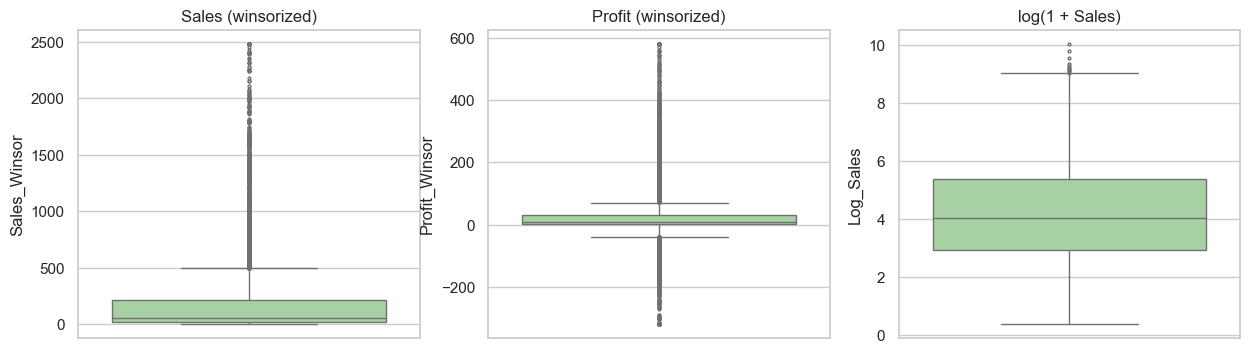

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df["Sales_Winsor"], ax=axes[0], color="#a1d99b", fliersize=2).set_title("Sales (winsorized)")
sns.boxplot(y=df["Profit_Winsor"], ax=axes[1], color="#a1d99b", fliersize=2).set_title("Profit (winsorized)")
sns.boxplot(y=df["Log_Sales"], ax=axes[2], color="#a1d99b", fliersize=2).set_title("log(1 + Sales)")
plt.savefig("02_boxplots_after_treatment")

2.5 Feature engineering (domain Knowledge)

In [32]:
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Quarter"] = df["Order Date"].dt.quarter
df["Order Day of Week"] = df["Order Date"].dt.day_name()
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin"] = df["Profit"] / df["Sales"]
df["Unit Price"] = df["Sales"] / (df["Quantity"] * (1 - df["Discount"]))
df["Discount Band"] = pd.cut(
    df["Discount"], bins=[-0.001, 0, 0.2, 0.4, 1.0],
    labels=["No discount", "Low (1-20%)", "Medium (21-40%)", "High (>40%)"],
)
df["Is Loss"] = (df["Profit"] < 0).astype(int)
df["Order Size"] = df.groupby("Order ID")["Row ID"].transform("count")
df["Customer Orders"] = df.groupby("Customer ID")["Order ID"].transform("nunique")
df[["Order Year", "Shipping Days", "Profit Margin", "Unit Price", "Discount Band", "Is Loss", "Order Size", "Customer Orders"]].head()

,Order Year,Shipping Days,Profit Margin,Unit Price,Discount Band,Is Loss,Order Size,Customer Orders
0,2016,3,0.1600,130.98,No discount,0,2,3
1,2016,3,0.3000,243.98,No discount,0,2,3
2,2016,4,0.4700,7.31,No discount,0,1,5
3,2015,7,-0.4000,348.21,High (>40%),1,2,6
4,2015,7,0.1125,13.98,Low (1-20%),0,2,6


2.6 Save the cleaned dataset (reafable, un-encoded)

In [40]:
df.to_csv(PROCESSED_DIR / "superstore_cleaned.csv", index=False)
print("Saved:", PROCESSED_DIR / "superstore_cleaned.csv", df.shape)

Saved: data\processed\superstore_cleaned.csv (9994, 38)


2.7 Encoding categorical variables 

In [39]:
model_df = df.copy() # creates a seprate copy so orginal df remains unchanged

onehot_cols = ["Ship Mode", "Segment", "Region", "Category"]
model_df = pd.get_dummies(model_df, columns=onehot_cols, drop_first=False, dtype=int) # this converts each category into a seperate 0/1 columns

for c in ["Sub-Category", "State"]:
    model_df[f"{c}_Encoded"] = LabelEncoder().fit_transform(model_df[c]) # This converts text categories into numerical labels.

band_order = {"No discount": 0, "Low (1-20%)": 1, "Medium (21-40%)": 2, "High (>40%)": 3} # define an ordered numerical representation for Discount Band.
model_df["Discount Band"] = model_df["Discount Band"].astype(str).map(band_order)

print("Columns after encoding:", model_df.shape[1])
model_df.filter(regex="^(Ship Mode_|Segment_|Region_|Category_)|_Encoded$").head()

Columns after encoding: 50


,Ship Mode_First Class,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class,Segment_Consumer,Segment_Corporate,Segment_Home Office,Region_Central,Region_East,Region_South,Region_West,Category_Furniture,Category_Office Supplies,Category_Technology,Sub-Category_Encoded,State_Encoded
0,0,0,1,0,1,0,0,0,0,1,0,1,0,0,4,15
1,0,0,1,0,1,0,0,0,0,1,0,1,0,0,5,15
2,0,0,1,0,0,1,0,0,0,0,1,0,1,0,10,3
3,0,0,0,1,1,0,0,0,0,1,0,1,0,0,16,8
4,0,0,0,1,1,0,0,0,0,1,0,0,1,0,14,8


2.8 Scaling numerical features

In [41]:
to_scale = ["Sales_Winsor", "Log_Sales", "Quantity", "Discount", "Profit_Winsor",
            "Profit Margin", "Unit Price", "Shipping Days", "Order Size", "Customer Orders"]
scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(model_df[to_scale]),
                      columns=[f"{c}_Scaled" for c in to_scale], index=model_df.index)
model_df = pd.concat([model_df, scaled], axis=1)
print(scaled.describe().loc[["mean", "std"]].round(3))

# Save the model-ready dataset (identifiers/text dropped, everything numeric)
drop_for_model = ["Row ID", "Order ID", "Order Date", "Ship Date", "Customer ID", "Customer Name",
                  "Country", "City", "State", "Postal Code", "Product ID", "Product Name",
                  "Sub-Category", "Order Day of Week", "Year-Month"]
model_ready = model_df.drop(columns=drop_for_model)
model_ready.to_csv(PROCESSED_DIR / "superstore_model_ready.csv", index=False)
print("Saved:", PROCESSED_DIR / "superstore_model_ready.csv", model_ready.shape)

      Sales_Winsor_Scaled  Log_Sales_Scaled  Quantity_Scaled  Discount_Scaled  \
mean                  0.0               0.0              0.0             -0.0   
std                   1.0               1.0              1.0              1.0   

      Profit_Winsor_Scaled  Profit Margin_Scaled  Unit Price_Scaled  \
mean                  -0.0                   0.0               -0.0   
std                    1.0                   1.0                1.0   

      Shipping Days_Scaled  Order Size_Scaled  Customer Orders_Scaled  
mean                  -0.0               -0.0                    -0.0  
std                    1.0                1.0                     1.0  
Saved: data\processed\superstore_model_ready.csv (9994, 45)


3. Exploratory Data Analysis (EDA)


3.1 Descriptive statistics

In [ ]:
num_summary = df[["Sales", "Quantity", "Discount", "Profit", "Profit Margin", "Shipping Days"]].describe().T
num_summary["skew"] = df[["Sales", "Quantity", "Discount", "Profit", "Profit Margin", "Shipping Days"]].skew()
print(num_summary.round(2))

                count    mean     std      min    25%    50%     75%  \
Sales          9994.0  229.86  623.25     0.44  17.28  54.49  209.94   
Quantity       9994.0    3.79    2.23     1.00   2.00   3.00    5.00   
Discount       9994.0    0.16    0.21     0.00   0.00   0.20    0.20   
Profit         9994.0   28.66  234.26 -6599.98   1.73   8.67   29.36   
Profit Margin  9994.0    0.12    0.47    -2.75   0.08   0.27    0.36   
Shipping Days  9994.0    3.96    1.75     0.00   3.00   4.00    5.00   

                    max   skew  
Sales          22638.48  12.97  
Quantity          14.00   1.28  
Discount           0.80   1.68  
Profit          8399.98   7.56  
Profit Margin      0.50  -2.89  
Shipping Days      7.00  -0.42  


In [43]:
cat_cols = ["Ship Mode", "Segment", "Region", "Category", "Sub-Category"]
for c in cat_cols:
    t = df[c].value_counts().to_frame("rows")
    t["% rows"] = (t["rows"] / len(df) * 100).round(1)
    t["Sales"] = df.groupby(c)["Sales"].sum().round(0)
    t["Profit"] = df.groupby(c)["Profit"].sum().round(0)
    t["Margin %"] = (t["Profit"] / t["Sales"] * 100).round(1)
    print(f"\n--- {c} ---")
    print(t)


--- Ship Mode ---
                rows  % rows      Sales    Profit  Margin %
Ship Mode                                                  
Standard Class  5968    59.7  1358216.0  164089.0      12.1
Second Class    1945    19.5   459194.0   57447.0      12.5
First Class     1538    15.4   351428.0   48970.0      13.9
Same Day         543     5.4   128363.0   15892.0      12.4

--- Segment ---
             rows  % rows      Sales    Profit  Margin %
Segment                                                 
Consumer     5191    51.9  1161401.0  134119.0      11.5
Corporate    3020    30.2   706146.0   91979.0      13.0
Home Office  1783    17.8   429653.0   60299.0      14.0

--- Region ---
         rows  % rows     Sales    Profit  Margin %
Region                                             
West     3203    32.0  725458.0  108418.0      14.9
East     2848    28.5  678781.0   91523.0      13.5
Central  2323    23.2  501240.0   39706.0       7.9
South    1620    16.2  391722.0   46749.0  

3.2 Distribution (histograms and density plots)

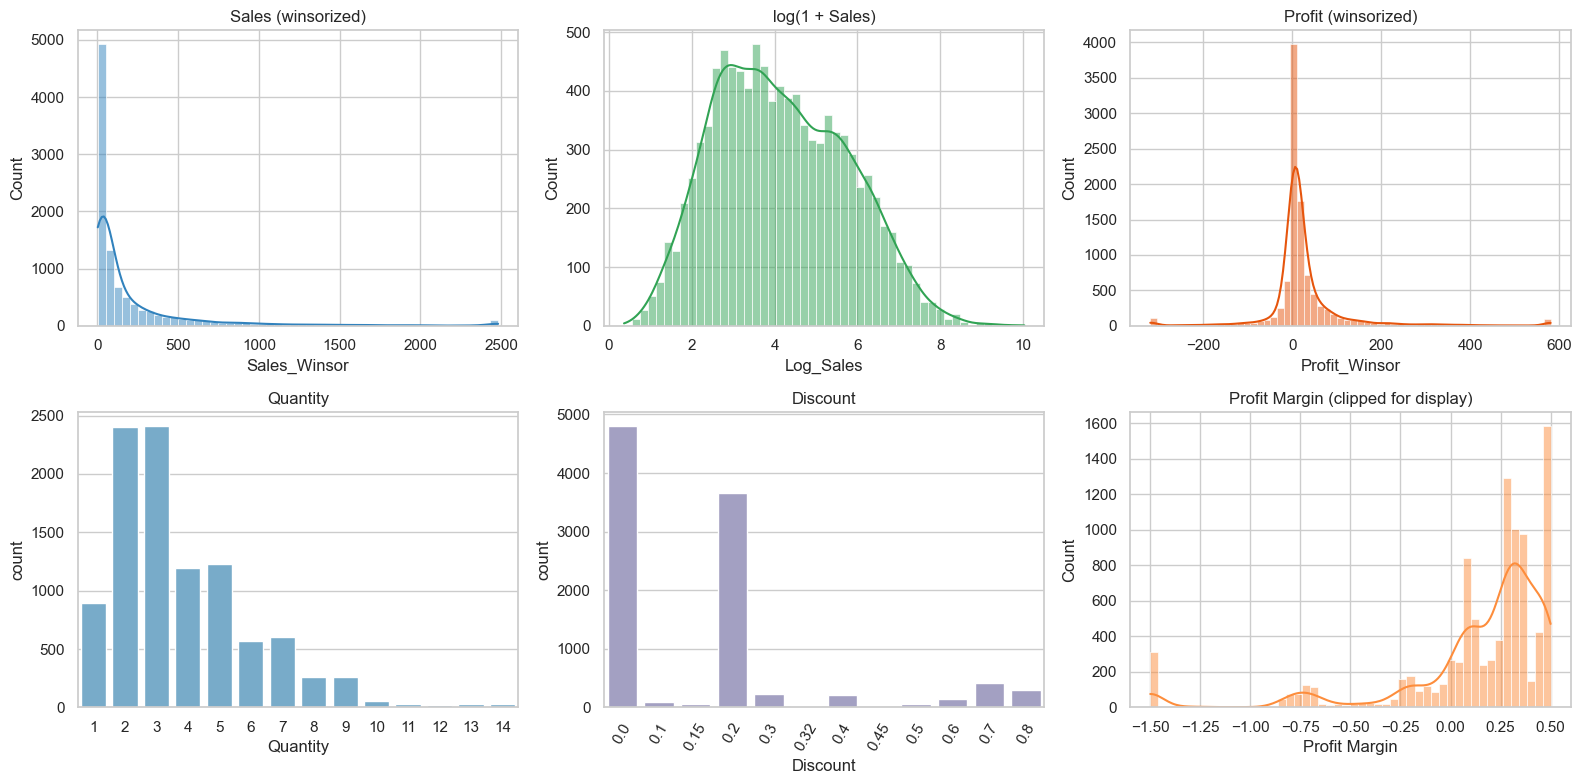

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(df["Sales_Winsor"], bins=50, kde=True, ax=axes[0, 0], color="#3182bd").set_title("Sales (winsorized)")
sns.histplot(df["Log_Sales"], bins=50, kde=True, ax=axes[0, 1], color="#31a354").set_title("log(1 + Sales)")
sns.histplot(df["Profit_Winsor"], bins=60, kde=True, ax=axes[0, 2], color="#e6550d").set_title("Profit (winsorized)")
sns.countplot(x=df["Quantity"], ax=axes[1, 0], color="#6baed6").set_title("Quantity")
sns.countplot(x=df["Discount"], ax=axes[1, 1], color="#9e9ac8").set_title("Discount")
axes[1, 1].tick_params(axis="x", rotation=60)
sns.histplot(df["Profit Margin"].clip(-1.5, 0.6), bins=50, kde=True, ax=axes[1, 2], color="#fd8d3c").set_title("Profit Margin (clipped for display)")
save_fig("03_distributions")

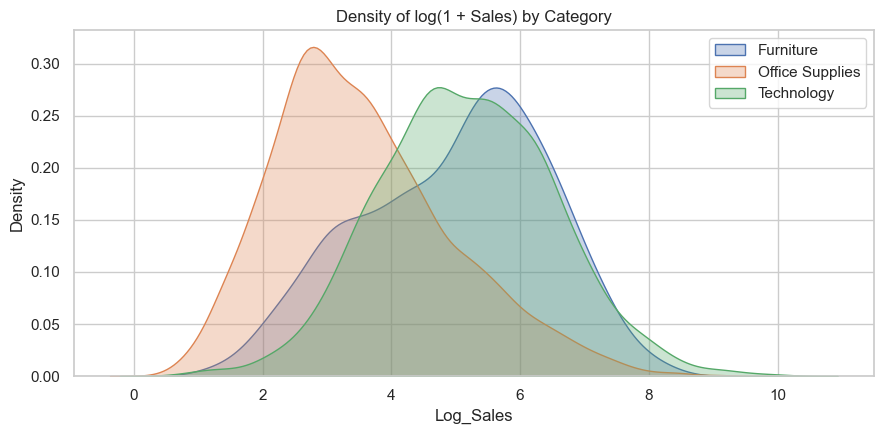

In [45]:
plt.figure(figsize=(9, 4.5))
for cat in df["Category"].unique():
    sns.kdeplot(df.loc[df["Category"] == cat, "Log_Sales"], label=cat, fill=True, alpha=0.3)
plt.title("Density of log(1 + Sales) by Category")
plt.legend()
save_fig("04_density_sales_by_category")

3.3 Relationsips between variables

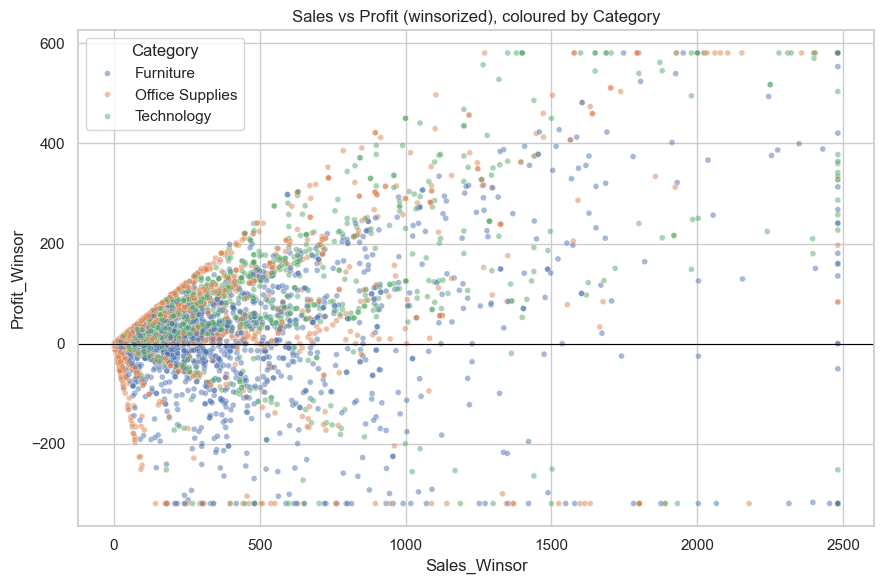

In [46]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Sales_Winsor", y="Profit_Winsor", hue="Category", alpha=0.5, s=18)
plt.axhline(0, color="black", lw=0.8)
plt.title("Sales vs Profit (winsorized), coloured by Category")
save_fig("05_scatter_sales_vs_profit")

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_16496\4286363463.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Discount Band", y="Profit_Winsor", ax=axes[0], palette="RdYlGn_r")


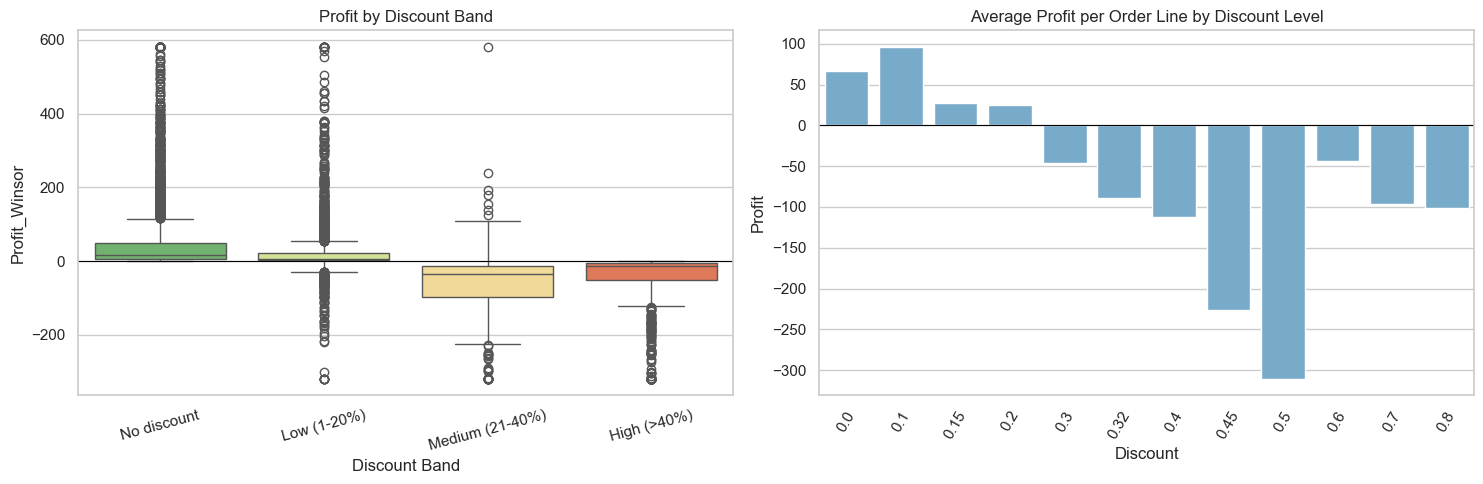

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="Discount Band", y="Profit_Winsor", ax=axes[0], palette="RdYlGn_r")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("Profit by Discount Band")
axes[0].tick_params(axis="x", rotation=15)
disc = df.groupby("Discount")["Profit"].mean().reset_index()
sns.barplot(data=disc, x="Discount", y="Profit", ax=axes[1], color="#6baed6")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Average Profit per Order Line by Discount Level")
axes[1].tick_params(axis="x", rotation=60)
save_fig("06_discount_vs_profit")

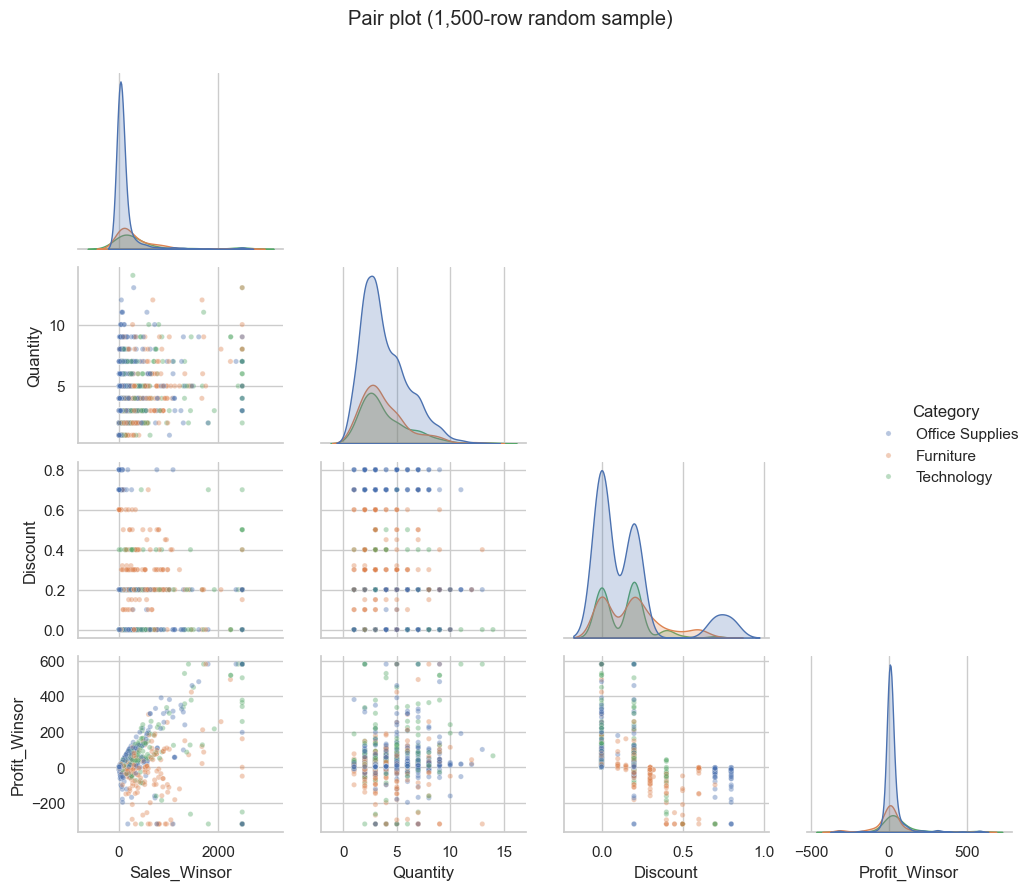

In [48]:
# Pair plot on a random sample (keeps it fast and legible)
pair_cols = ["Sales_Winsor", "Quantity", "Discount", "Profit_Winsor", "Category"]
pp = sns.pairplot(df[pair_cols].sample(1500, random_state=42), hue="Category",
                  corner=True, plot_kws={"alpha": 0.4, "s": 14}, height=2.2)
pp.fig.suptitle("Pair plot (1,500-row random sample)", y=1.01)
save_fig("07_pairplot")

3.4 Correlation analysis

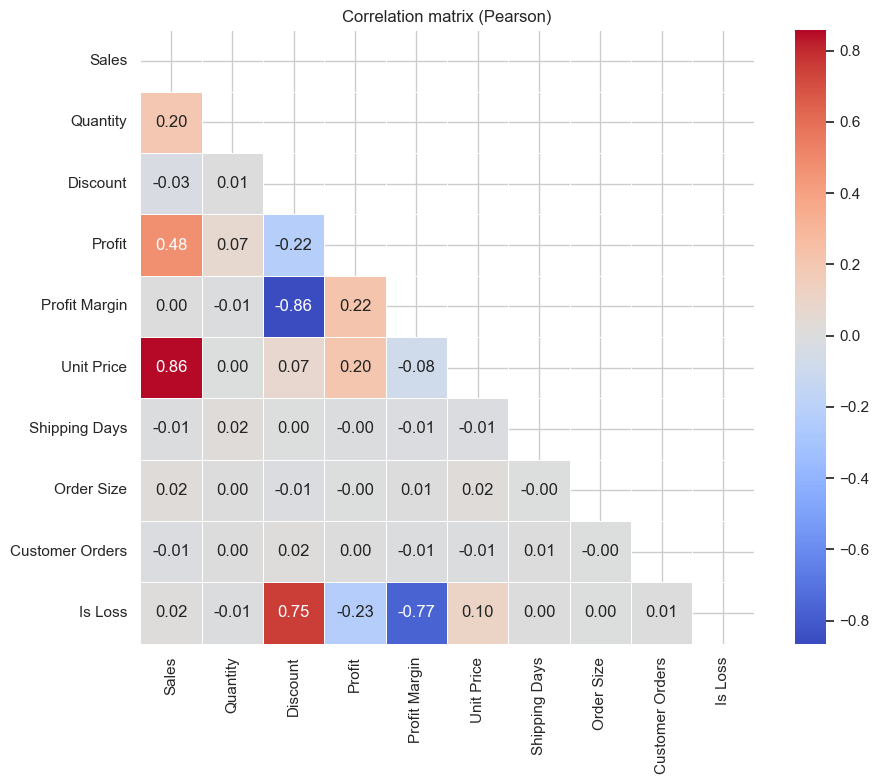

Spearman correlation (rank-based, robust to outliers):
          Sales  Quantity  Discount  Profit
Sales      1.00      0.33     -0.06    0.52
Quantity   0.33      1.00     -0.00    0.23
Discount  -0.06     -0.00      1.00   -0.54
Profit     0.52      0.23     -0.54    1.00


In [49]:
corr_cols = ["Sales", "Quantity", "Discount", "Profit", "Profit Margin", "Unit Price",
             "Shipping Days", "Order Size", "Customer Orders", "Is Loss"]
corr = df[corr_cols].corr(method="pearson")
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation matrix (Pearson)")
save_fig("08_correlation_heatmap")

# Spearman is more reliable for skewed data, so compare the key pairs
spear = df[["Sales", "Quantity", "Discount", "Profit"]].corr(method="spearman")
print("Spearman correlation (rank-based, robust to outliers):")
print(spear.round(2))

3.5 Trends over time

               Sales   Profit  Margin %  Sales growth %
Order Year                                             
2014        484247.5  49544.0      10.2             NaN
2015        470532.5  61618.6      13.1            -2.8
2016        609205.6  81795.2      13.4            29.5
2017        733215.3  93439.3      12.7            20.4


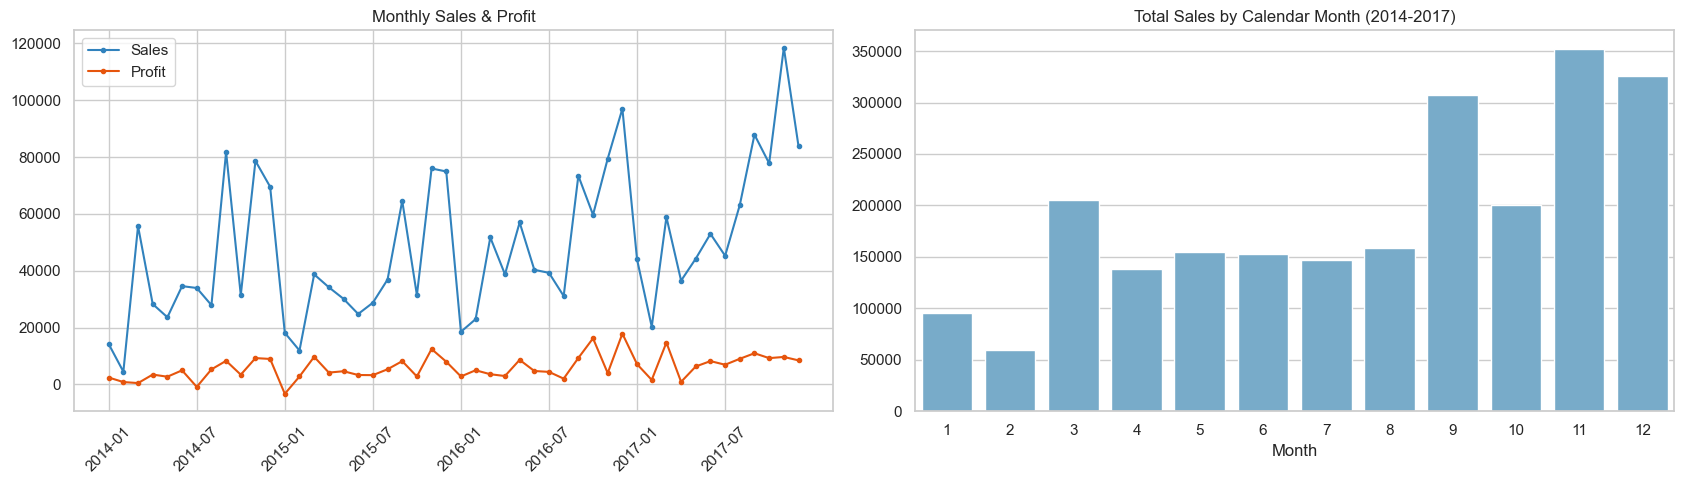

In [50]:
yearly = df.groupby("Order Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
yearly["Sales growth %"] = yearly["Sales"].pct_change() * 100
print(yearly.round(1))

monthly = df.groupby("Year-Month").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
axes[0].plot(monthly["Year-Month"], monthly["Sales"], marker="o", ms=3, label="Sales", color="#3182bd")
axes[0].plot(monthly["Year-Month"], monthly["Profit"], marker="o", ms=3, label="Profit", color="#e6550d")
axes[0].set_xticks(range(0, len(monthly), 6))
axes[0].set_xticklabels(monthly["Year-Month"][::6], rotation=45)
axes[0].set_title("Monthly Sales & Profit")
axes[0].legend()
season = df.groupby("Order Month")["Sales"].sum()
sns.barplot(x=season.index, y=season.values, ax=axes[1], color="#6baed6")
axes[1].set_title("Total Sales by Calendar Month (2014-2017)")
axes[1].set_xlabel("Month")
save_fig("09_time_trends")

3.6 Category, product, region, segment and shipping analysis

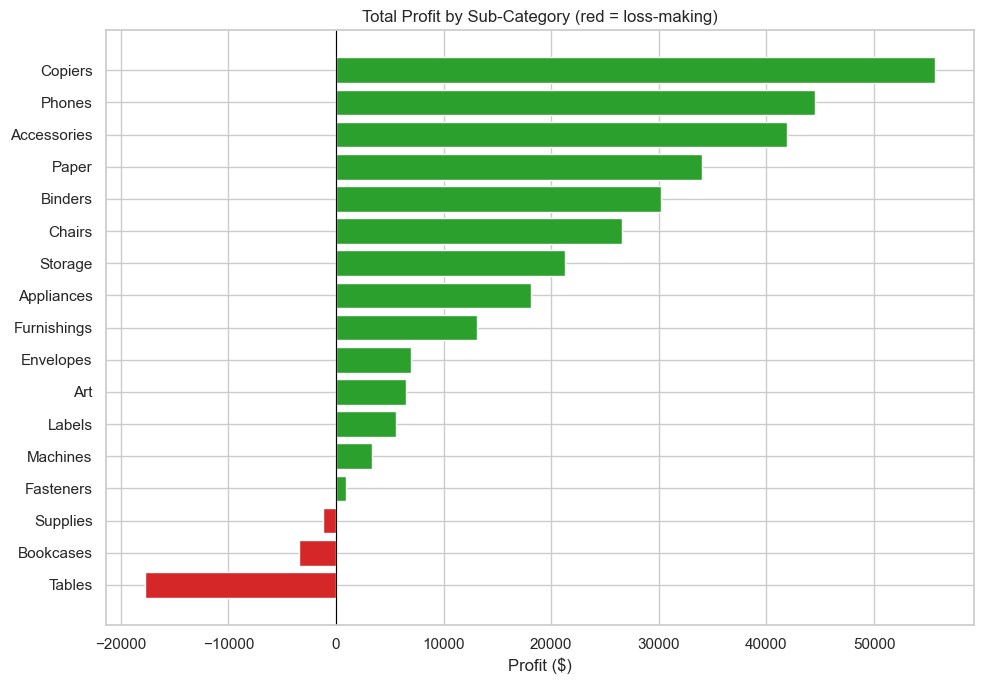

In [51]:
sub = df.groupby(["Category", "Sub-Category"]).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).reset_index()
sub = sub.sort_values("Profit")
plt.figure(figsize=(10, 7))
colors = ["#d62728" if p < 0 else "#2ca02c" for p in sub["Profit"]]
plt.barh(sub["Sub-Category"], sub["Profit"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Total Profit by Sub-Category (red = loss-making)")
plt.xlabel("Profit ($)")
save_fig("10_profit_by_subcategory")

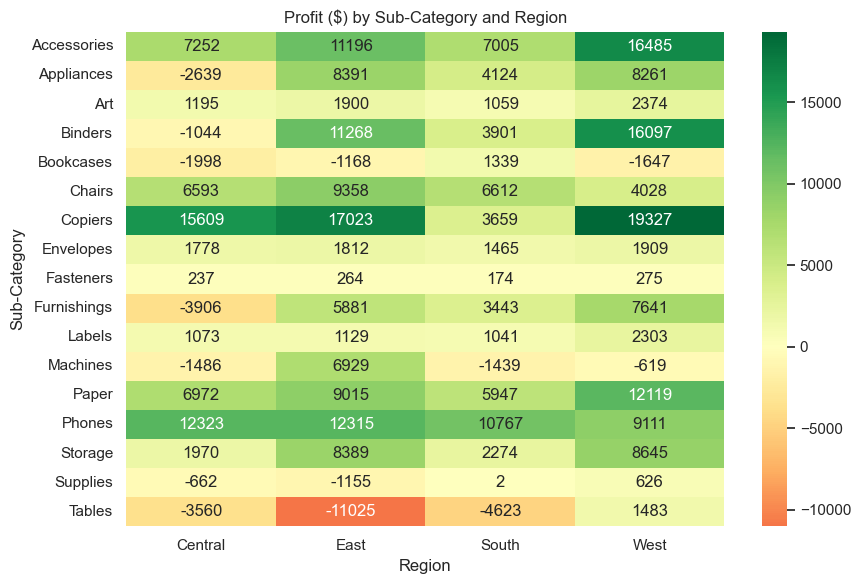

In [52]:
fig, ax = plt.subplots(figsize=(9, 6))
pivot = df.pivot_table(index="Sub-Category", columns="Region", values="Profit", aggfunc="sum")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=ax)
ax.set_title("Profit ($) by Sub-Category and Region")
save_fig("13_subcategory_region_heatmap")

4. Key Insights

In [56]:
# Overall performance
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
margin = total_profit / total_sales * 100

# Yearly sales
yearly = df.groupby("Order Year")["Sales"].sum().to_frame("Sales")
yearly["Sales growth %"] = yearly["Sales"].pct_change() * 100

# Product, category, region and segment analysis
sub_p = df.groupby("Sub-Category")["Profit"].sum().sort_values()
cat_m = df.groupby("Category").apply(lambda x: x["Profit"].sum()/x["Sales"].sum()*100)
reg_m = df.groupby("Region").apply(lambda x: x["Profit"].sum()/x["Sales"].sum()*100)
seg_m = df.groupby("Segment").apply(lambda x: x["Profit"].sum()/x["Sales"].sum()*100)

# State profit
state = df.groupby("State")["Profit"].sum().sort_values()

# Discount analysis
band = df.groupby("Discount Band").agg(
    Lines=("Sales", "size"),
    Profit=("Profit", "sum"),
    Sales=("Sales", "sum")
)
band["Margin %"] = band["Profit"] / band["Sales"] * 100

# Monthly sales and shipping
top_months = df.groupby("Order Month")["Sales"].sum().nlargest(3)
ship = df.groupby("Ship Mode")["Shipping Days"].mean()

# Correlations
discount_profit_corr = df["Discount"].corr(df["Profit"])
sales_profit_corr = df["Sales"].corr(df["Profit"])

# Customer and loss analysis
customer_sales = df.groupby("Customer ID")["Sales"].sum()
top10 = int(len(customer_sales) * 0.1)
top10_share = customer_sales.nlargest(top10).sum() / total_sales * 100
loss_lines = df["Is Loss"].mean() * 100

# Display key results
print(f"Total Sales: ${total_sales:,.0f}")
print(f"Total Profit: ${total_profit:,.0f}")
print(f"Profit Margin: {margin:.1f}%")
print(f"Top 3 Sales Months: {top_months.index.tolist()}")
print(f"Top 10% Customer Sales Share: {top10_share:.1f}%")
print(f"Loss-making Lines: {loss_lines:.1f}%")
print("\nMost Profitable States:")
print(state.tail(3))
print("\nLeast Profitable States:")
print(state.head(3))

Total Sales: $2,297,201
Total Profit: $286,397
Profit Margin: 12.5%
Top 3 Sales Months: [11, 12, 9]
Top 10% Customer Sales Share: 30.6%
Loss-making Lines: 18.7%

Most Profitable States:
State
Washington    33402.6517
New York      74038.5486
California    76381.3871
Name: Profit, dtype: float64

Least Profitable States:
State
Texas          -25729.3563
Ohio           -16971.3766
Pennsylvania   -15559.9603
Name: Profit, dtype: float64


5. Recommenations and feature Selection

In [2]:
# Final sanity checks on the saved outputs
cleaned = pd.read_csv(PROCESSED_DIR / "superstore_cleaned.csv")
ready = pd.read_csv(PROCESSED_DIR / "superstore_model_ready.csv")
assert cleaned.isna().sum().sum() == 0 and ready.isna().sum().sum() == 0
assert ready.select_dtypes(exclude="number").empty
print("All checks passed.", cleaned.shape, ready.shape)

All checks passed. (9994, 38) (9994, 45)
